In [1]:
import pandas as pd 
df = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data',header=None,
                 names=['Sepal Length','Sepal Width','Petal Length','Petal Width','Class'])
df


,Sepal Length,Sepal Width,Petal Length,Petal Width,Class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [2]:
df['Class'].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [3]:
df[df['Class'] == 'Iris-setosa'].head()

,Sepal Length,Sepal Width,Petal Length,Petal Width,Class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df[df['Class'] == 'Iris-virginica'].head()

,Sepal Length,Sepal Width,Petal Length,Petal Width,Class
100,6.3,3.3,6.0,2.5,Iris-virginica
101,5.8,2.7,5.1,1.9,Iris-virginica
102,7.1,3.0,5.9,2.1,Iris-virginica
103,6.3,2.9,5.6,1.8,Iris-virginica
104,6.5,3.0,5.8,2.2,Iris-virginica


In [5]:
# How many missing values
df.isnull().sum()

Sepal Length    0
Sepal Width     0
Petal Length    0
Petal Width     0
Class           0
dtype: int64

In [6]:
df[df['Class'] == 'Iris-setosa'].mean(numeric_only=True)

Sepal Length    5.006
Sepal Width     3.418
Petal Length    1.464
Petal Width     0.244
dtype: float64

In [7]:
df[df['Class'] == 'Iris-versicolor'].mean(numeric_only=True)

Sepal Length    5.936
Sepal Width     2.770
Petal Length    4.260
Petal Width     1.326
dtype: float64

In [8]:
df[df['Class'] == 'Iris-virginica'].mean(numeric_only=True)

Sepal Length    6.588
Sepal Width     2.974
Petal Length    5.552
Petal Width     2.026
dtype: float64

In [9]:
df[df['Class'] == 'Iris-setosa']

,Sepal Length,Sepal Width,Petal Length,Petal Width,Class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


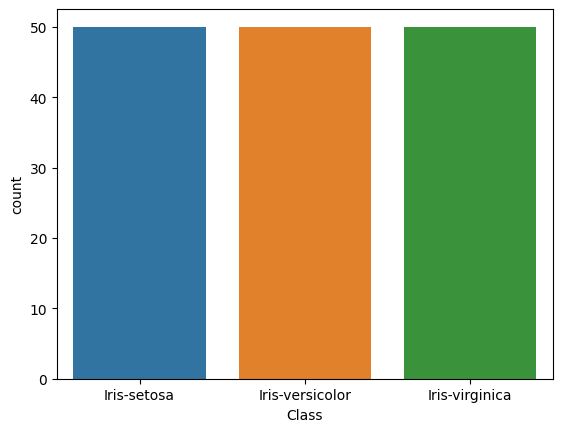

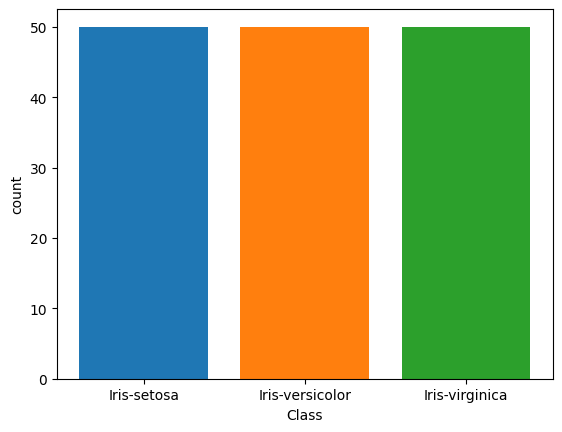

In [12]:
# importing packages
import seaborn as sns
import matplotlib.pyplot as plt


# Add hue='Class' to apply different colors
sns.countplot(x='Class', data=df, hue='Class')
plt.show()

# 1. Count the occurrences of each class
counts = df['Class'].value_counts()

# 2. Plot using plt.bar and provide a list of colors
plt.bar(counts.index, counts.values, color=['#1f77b4', '#ff7f0e', '#2ca02c'])

# 3. Add labels to match the Seaborn output
plt.xlabel('Class')
plt.ylabel('count')
plt.show()

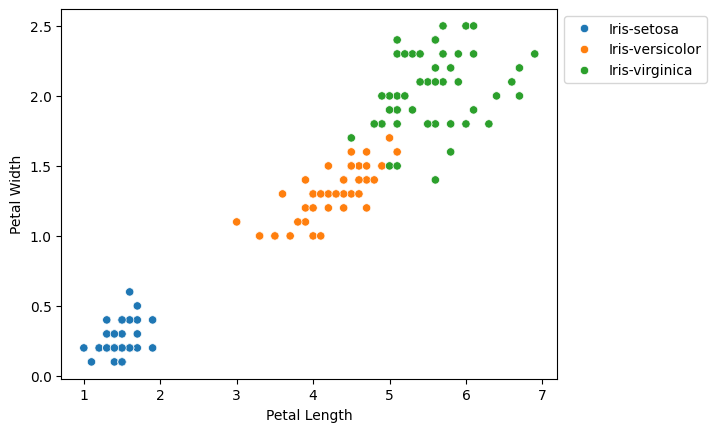

In [13]:
sns.scatterplot(x='Petal Length', y='Petal Width',
                hue='Class', data=df, )

# Placing Legend outside the Figure
plt.legend(bbox_to_anchor=(1, 1), loc=2)

plt.show()

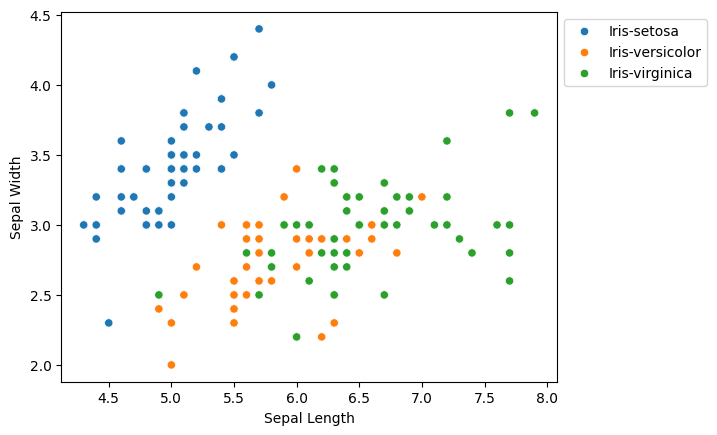

In [14]:
# Plot (scatter) Sepal length and Sepal Width 
sns.scatterplot(x='Sepal Length', y='Sepal Width', hue='Class', data=df, )

# Placing Legend outside the Figure
plt.legend(bbox_to_anchor=(1, 1), loc=2)

plt.show()

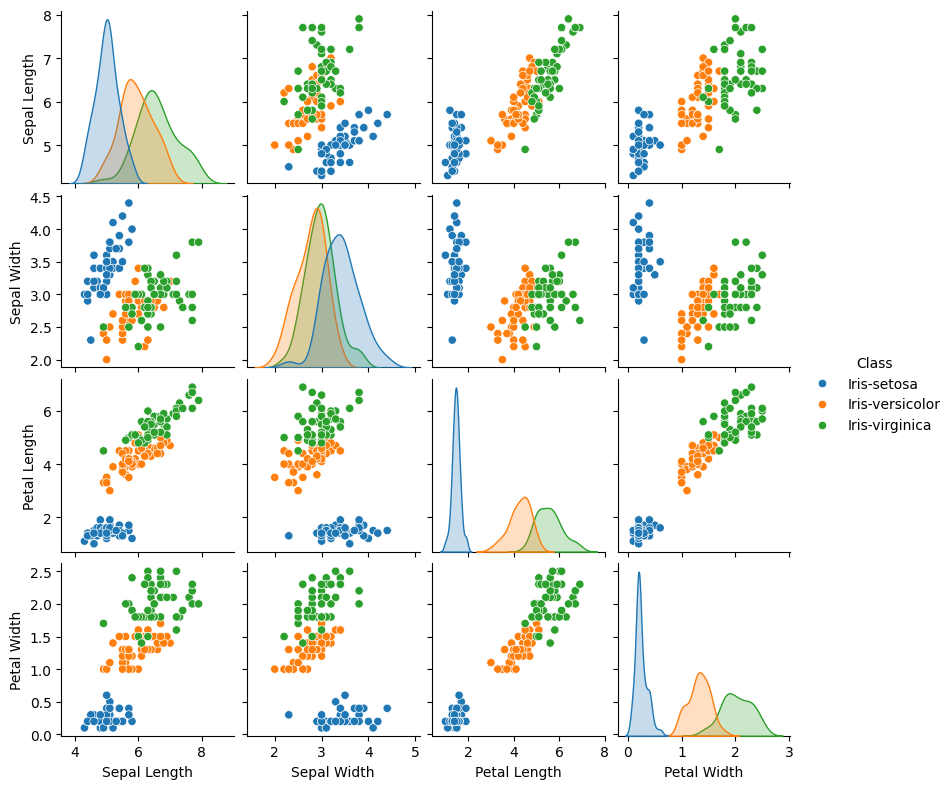

In [15]:
sns.pairplot(df, hue='Class', height=2)

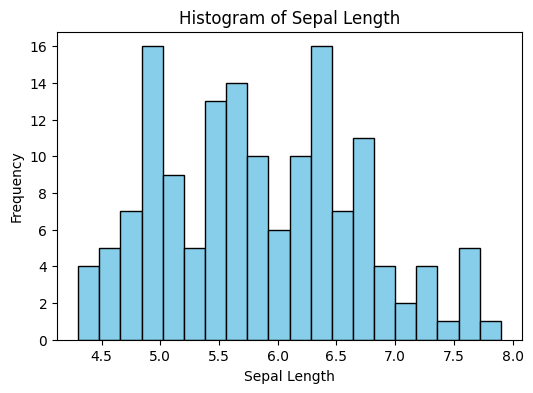

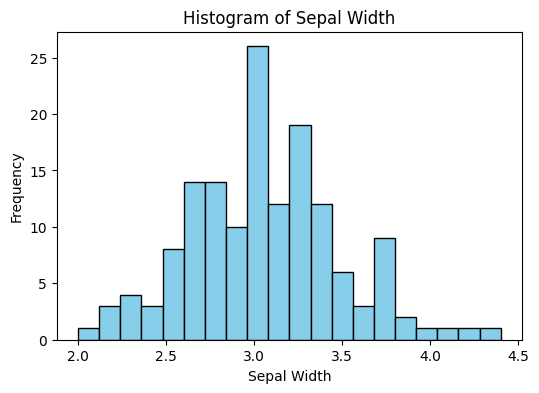

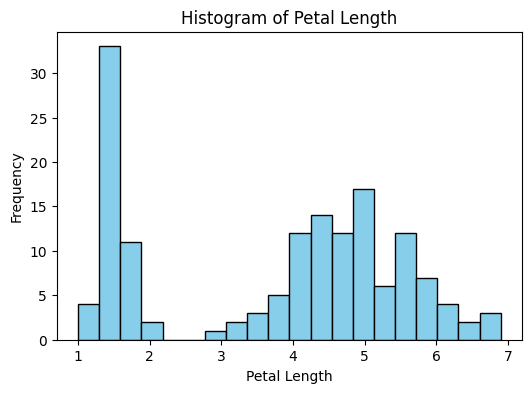

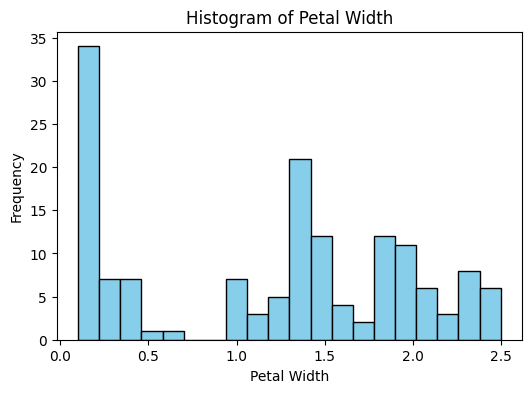

In [16]:
import matplotlib.pyplot as plt

# Define the numerical columns in your dataset
features = ['Sepal Length', 'Sepal Width', 'Petal Length', 'Petal Width']

# Loop through each feature and create a new plot one by one
for feature in features:
    plt.figure(figsize=(6, 4)) # Create a new figure for each histogram
    plt.hist(df[feature], bins=20, color='skyblue', edgecolor='black')
    
    # Add titles and labels
    plt.title(f'Histogram of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    
    # Display the plot before moving to the next one
    plt.show()

In [19]:
# Calculate the correlation matrix, excluding the non-numeric 'Class' column
df.corr(numeric_only=True)

,Sepal Length,Sepal Width,Petal Length,Petal Width
Sepal Length,1.000000,-0.109369,0.871754,0.817954
Sepal Width,-0.109369,1.000000,-0.420516,-0.356544
Petal Length,0.871754,-0.420516,1.000000,0.962757
Petal Width,0.817954,-0.356544,0.962757,1.000000


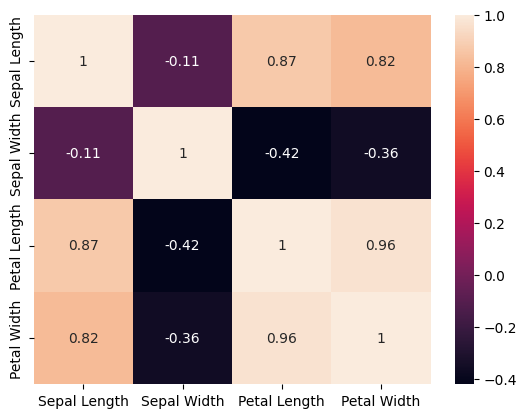

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
corr_matrix = df.corr(numeric_only=True)

# Plot the heatmap
sns.heatmap(corr_matrix, annot=True)

plt.show()

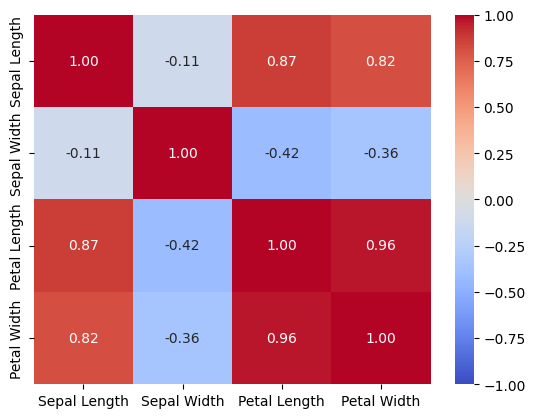

In [22]:
correlations = df.drop(columns="Class").corr()

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.show()

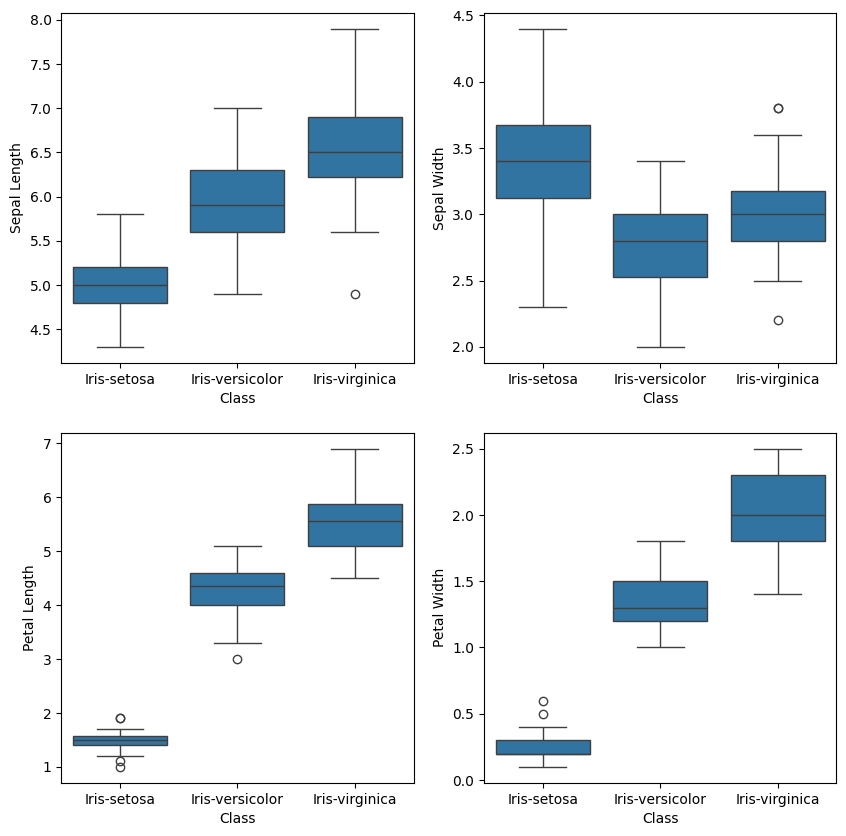

In [21]:
def graph(y):
    sns.boxplot(x="Class", y=y, data=df)

plt.figure(figsize=(10,10))

# Adding the subplot at the specified
# grid position
plt.subplot(221)
graph('Sepal Length')

plt.subplot(222)
graph('Sepal Width')

plt.subplot(223)
graph('Petal Length')

plt.subplot(224)
graph('Petal Width')

plt.show()